<center>

# **Banking Analysis**

</center>




**Problems Faced by the Bank -**

- The bank has a large and diverse customer base, but management lacks a clear understanding of customer financial behavior, profitability, and risk profiles.

- Existing reports do not effectively identify high-value customers, making it difficult to offer personalized services and improve customer retention.

- The bank is unable to accurately evaluate lending risk, customer loyalty, and investment advisor performance, resulting in inefficient business decisions.

- Limited data-driven insights lead to missed cross-selling opportunities, suboptimal resource allocation, and reduced operational efficiency.

In [92]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

excel_file = pd.ExcelFile("Banking.xlsx")

print(excel_file.sheet_names)

['Clients - Banking', 'Gender', 'Banking Relationship', 'Investment Advisor']


In [93]:
clients = pd.read_excel("Banking.xlsx", sheet_name='Clients - Banking')
gender = pd.read_excel("Banking.xlsx", sheet_name='Gender')
banking_relation = pd.read_excel('Banking.xlsx', sheet_name= "Banking Relationship")
investment_advisor = pd.read_excel('Banking.xlsx', sheet_name= "Investment Advisor")

df = clients.merge(gender, on='GenderId')
df= df.merge(banking_relation, on='BRId')
df= df.merge(investment_advisor, on= 'IAId')

df

,Client ID,Name,Age,Location ID,Joined Bank,Banking Contact,Nationality,Occupation,Fee Structure,Loyalty Classification,...,Foreign Currency Account,Business Lending,Properties Owned,Risk Weighting,BRId,GenderId,IAId,Gender,Banking Relationship,Investment Advisor
0,IND81288,Raymond Mills,24,34324,2019-05-06,Anthony Torres,American,Safety Technician IV,High,Jade,...,12249.9584,1.134475e+06,1,2,1,1,1,Male,Retail,Victor Dean
1,IND65833,Julia Spencer,23,42205,2001-12-10,Jonathan Hawkins,African,Software Consultant,High,Jade,...,61162.3089,2.000526e+06,1,3,2,1,2,Male,Institutional,Jeremy Porter
2,IND47499,Stephen Murray,27,7314,2010-01-25,Anthony Berry,European,Help Desk Operator,High,Gold,...,79071.7794,5.481376e+05,1,3,3,2,3,Female,Private Bank,Ernest Knight
3,IND72498,Virginia Garza,40,34594,2019-03-28,Steve Diaz,American,Geologist II,Mid,Silver,...,57513.6520,1.148402e+06,0,4,4,1,4,Male,Commercial,Eric Shaw
4,IND60181,Melissa Sanders,46,41269,2012-07-20,Shawn Long,American,Assistant Professor,Mid,Platinum,...,30012.1360,1.674412e+06,0,3,1,2,5,Female,Retail,Kevin Kim
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,IND66827,Earl Hall,82,8760,2014-10-09,Joshua Bennett,American,Accounting Assistant III,High,Gold,...,12947.3100,1.238860e+06,1,3,3,2,4,Female,Private Bank,Eric Shaw
2996,IND40556,Billy Williamson,44,32837,2009-02-05,Dennis Ruiz,European,Paralegal,Mid,Gold,...,23205.6900,2.771711e+05,1,2,3,2,5,Female,Private Bank,Kevin Kim
2997,IND72414,Victor Black,70,36088,2009-12-29,Joshua Ryan,American,Statistician IV,Low,Jade,...,30291.8112,5.029472e+05,2,2,3,2,6,Female,Private Bank,Victor Rogers
2998,IND46652,Andrew Ford,56,24871,2006-02-13,Nicholas Cunningham,European,Human Resources Assistant III,Mid,Jade,...,6413.1444,1.538369e+06,3,1,3,2,7,Female,Private Bank,Eugene Cunningham


In [94]:
print(f'Number of missing records {df.isna().sum()}\n')
print(f'Number of duplicated records {df.duplicated().sum()}\n')

print(f'Dataset Information:\n')
df.info()

summary = df.describe(include= [float,int])

print(f'Statistical Summary of Dataset :\n')

display(summary)

Number of missing records Client ID                   0
Name                        0
Age                         0
Location ID                 0
Joined Bank                 0
Banking Contact             0
Nationality                 0
Occupation                  0
Fee Structure               0
Loyalty Classification      0
Estimated Income            0
Superannuation Savings      0
Amount of Credit Cards      0
Credit Card Balance         0
Bank Loans                  0
Bank Deposits               0
Checking Accounts           0
Saving Accounts             0
Foreign Currency Account    0
Business Lending            0
Properties Owned            0
Risk Weighting              0
BRId                        0
GenderId                    0
IAId                        0
Gender                      0
Banking Relationship        0
Investment Advisor          0
dtype: int64

Number of duplicated records 0

Dataset Information:

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Dat

,Age,Location ID,Estimated Income,Superannuation Savings,Amount of Credit Cards,Credit Card Balance,Bank Loans,Bank Deposits,Checking Accounts,Saving Accounts,Foreign Currency Account,Business Lending,Properties Owned,Risk Weighting,BRId,GenderId,IAId
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3.000000e+03,3.000000e+03,3.000000e+03,3.000000e+03,3000.000000,3.000000e+03,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,51.039667,21563.323000,171305.034094,25531.599673,1.463667,3176.206780,5.913862e+05,6.715602e+05,3.210929e+05,2.329084e+05,29883.529774,8.667598e+05,1.518667,2.249333,2.559333,1.504000,10.425333
std,19.854760,12462.273017,111935.808260,16259.950770,0.676387,2497.094724,4.575570e+05,6.457169e+05,2.820796e+05,2.300078e+05,23109.924007,6.412303e+05,1.102145,1.131191,1.007713,0.500067,5.988242
min,17.000000,12.000000,15919.475400,1482.030000,1.000000,1.174800,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,44.998400,0.000000e+00,0.000000,1.000000,1.000000,1.000000,1.000000
25%,34.000000,10803.500000,82906.594300,12513.775000,1.000000,1236.633525,2.396281e+05,2.044004e+05,1.199475e+05,7.479441e+04,11916.546400,3.748251e+05,1.000000,1.000000,2.000000,1.000000,5.000000
50%,51.000000,21129.500000,142313.479600,22357.355000,1.000000,2560.800750,4.797934e+05,4.633165e+05,2.428157e+05,1.640866e+05,24341.187200,7.113147e+05,2.000000,2.000000,3.000000,2.000000,10.000000
75%,69.000000,32054.500000,242290.306650,35464.740000,2.000000,4522.633050,8.258130e+05,9.427546e+05,4.348749e+05,3.155750e+05,41966.390700,1.185110e+06,2.000000,3.000000,3.000000,2.000000,15.000000
max,85.000000,43369.000000,522330.259200,75963.900000,3.000000,13991.994000,2.667557e+06,3.890598e+06,1.969923e+06,1.724118e+06,124704.866000,3.825962e+06,3.000000,5.000000,4.000000,2.000000,22.000000


**Insights**
- Approx all financial feature shows very high variability

In [95]:
df.drop(columns=['Banking Contact','Location ID','BRId','GenderId','IAId'], inplace= True)

df['Joined Year'] = df['Joined Bank'].dt.year
df['Joined Month'] = df['Joined Bank'].dt.month_name()

df['Total Assets'] = (
    df['Bank Deposits']
    + df['Checking Accounts']
    + df['Saving Accounts']
    + df['Foreign Currency Account']
    + df['Superannuation Savings']
)

df['Total Debt'] = (
    df['Bank Loans']
    + df['Credit Card Balance']
)

df['Net Financial Position'] = (
    df['Total Assets']
    - df['Total Debt']
)

df['Deposit to Income Ratio'] = (
    df['Bank Deposits']
    / df['Estimated Income']
)

df['Loan to Income Ratio'] = (
    df['Bank Loans']
    / df['Estimated Income']
)

df['Customer Tenure (Years)'] = (
    pd.Timestamp.today() - df['Joined Bank']
).dt.days / 365

df['Age_label'] = pd.qcut(df['Age'],4 ,labels=['Young Adult', 'Middle_Age Adult', 'Adults' ,'Senior Citizen'] )


<Axes: xlabel='Joined Year'>

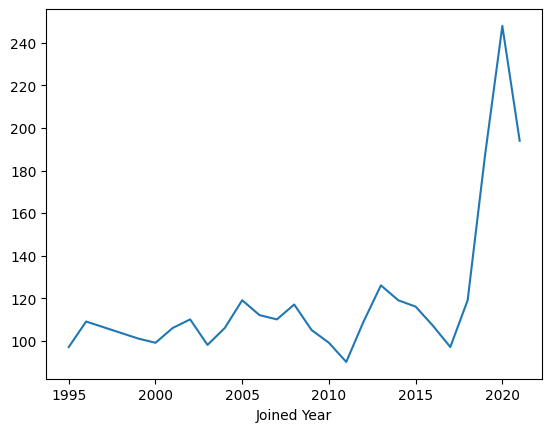

In [96]:
yearwise_client = df['Joined Year'].value_counts().sort_index()
sns.lineplot(x=yearwise_client.index , y= yearwise_client.values)


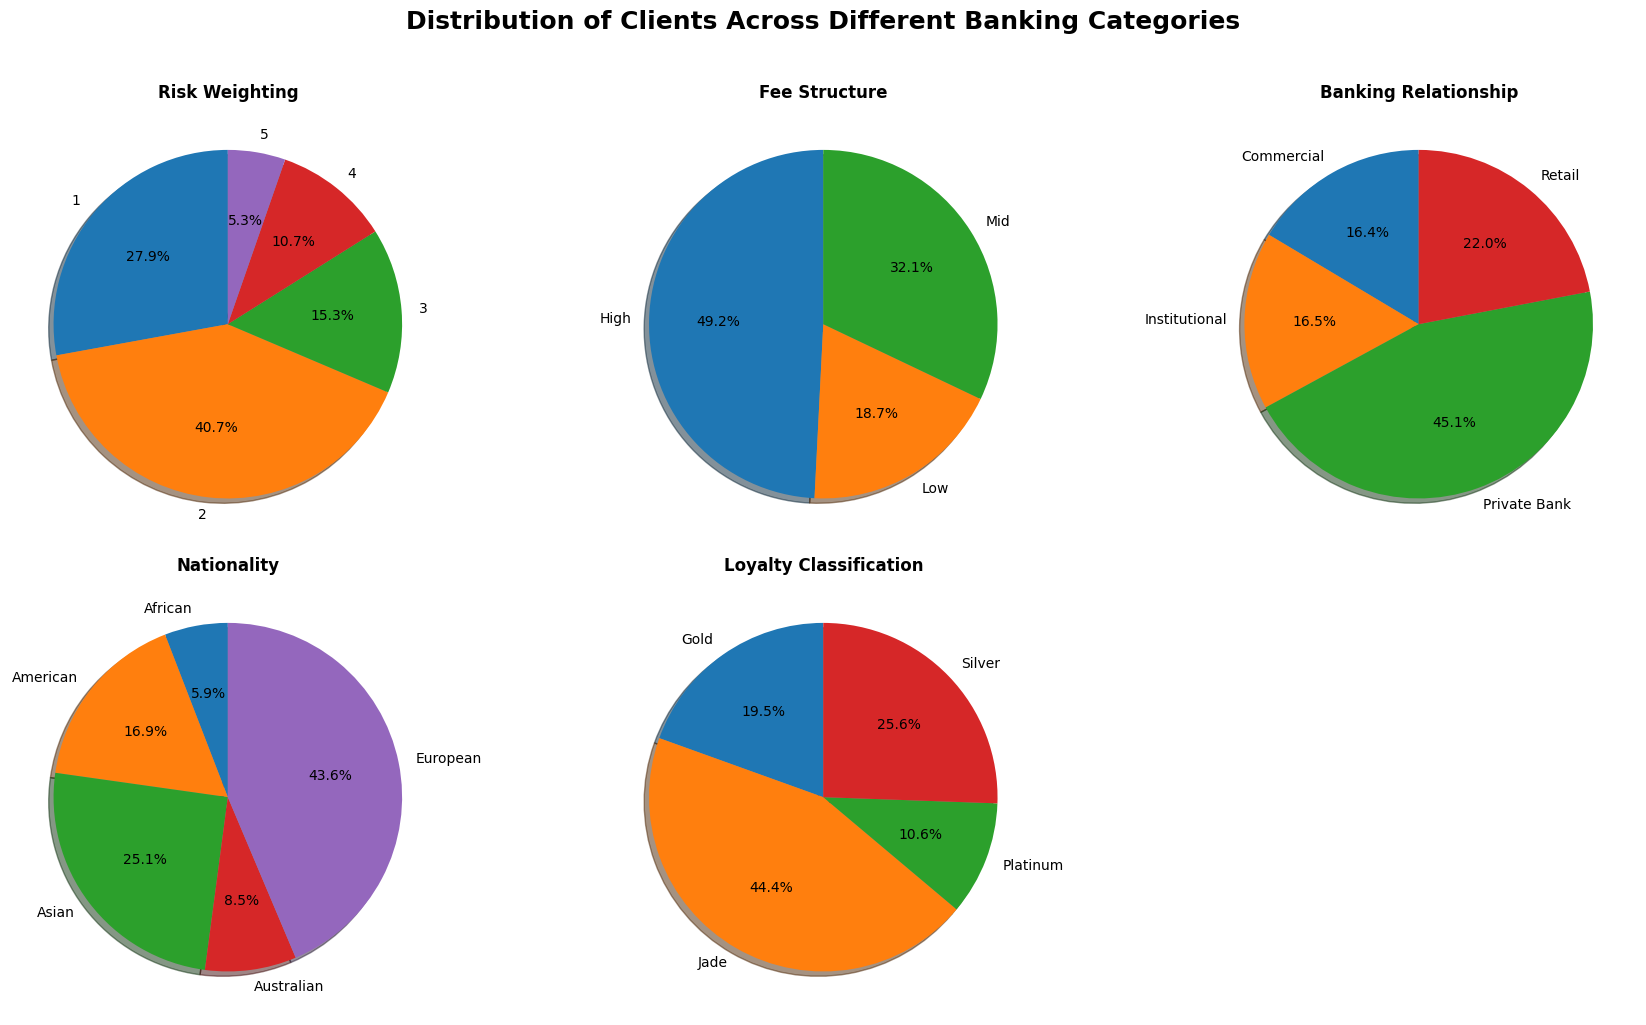

In [97]:
import matplotlib.pyplot as plt



# Count values
client_by_property = df.groupby("Properties Owned")["Client ID"].count()
client_by_relationship = df.groupby("Banking Relationship")["Client ID"].count()
client_by_risk = df.groupby("Risk Weighting")["Client ID"].count()
client_by_nationality = df.groupby("Nationality")["Client ID"].count()
client_by_fee = df.groupby("Fee Structure")["Client ID"].count()
client_by_loyalty = df.groupby("Loyalty Classification")["Client ID"].count()

# Create a 2x3 grid of subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))


fig.suptitle(
    "Distribution of Clients Across Different Banking Categories",
    fontsize=18,
    fontweight="bold",
    y=1.02  # Moves the title slightly upward
)

# Flatten the axes array for easier indexing
axes = axes.flatten()

# Pie Chart 1 - Risk Weighting
axes[0].pie(
    client_by_risk,
    labels=client_by_risk.index,
    autopct="%1.1f%%",
    startangle=90,
    shadow=True
)
axes[0].set_title("Risk Weighting", fontweight= "bold")

# Pie Chart 2 - Fee Structure
axes[1].pie(
    client_by_fee,
    labels=client_by_fee.index,
    autopct="%1.1f%%",
    startangle=90,
    shadow=True
)
axes[1].set_title("Fee Structure", fontweight= "bold")

# Pie Chart 3 - Banking Relationship
axes[2].pie(
    client_by_relationship,
    labels=client_by_relationship.index,
    autopct="%1.1f%%",
    startangle=90,
    shadow=True
)
axes[2].set_title("Banking Relationship", fontweight= "bold")

# Pie Chart 4 - Nationality
axes[3].pie(
    client_by_nationality,
    labels=client_by_nationality.index,
    autopct="%1.1f%%",
    startangle=90,
    shadow=True
)
axes[3].set_title("Nationality", fontweight= "bold")

# Pie Chart 5 - Loyalty Classification
axes[4].pie(
    client_by_loyalty,
    labels=client_by_loyalty.index,
    autopct="%1.1f%%",
    startangle=90,
    shadow=True
)
axes[4].set_title("Loyalty Classification", fontweight= "bold")



# Remove the unused subplot
fig.delaxes(axes[5])

# Keep pie charts circular
for ax in axes[:-1]:
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Total Assests(in Billion)')

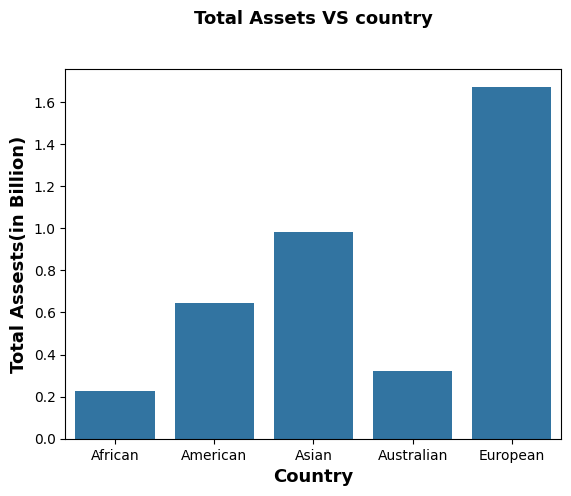

In [98]:
country_wise_assest = df.groupby('Nationality')['Total Assets'].sum()/ 1_000_000_000

sns.barplot( x= country_wise_assest.index , y= country_wise_assest.values)
plt.title("Total Assets VS country",y=1.10, fontsize=13, fontweight='bold')
plt.xlabel("Country", fontsize=13, fontweight='bold')
plt.ylabel("Total Assests(in Billion)", fontsize=13, fontweight='bold')


Text(0, 0.5, 'Loan to Income Ratio')

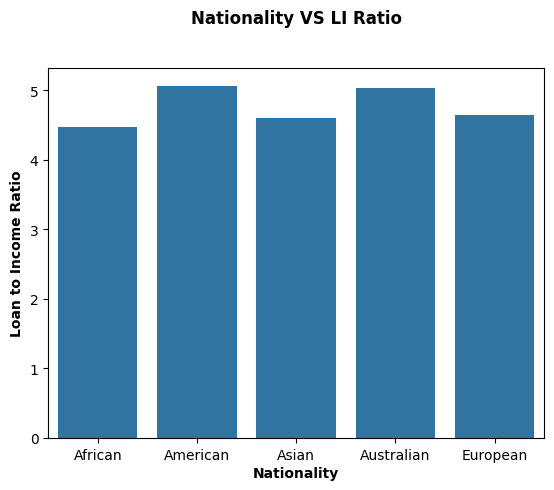

In [99]:
nation_wise_avg_LI_ratio = df.groupby('Nationality')['Loan to Income Ratio'].mean()

sns.barplot( x= nation_wise_avg_LI_ratio.index , y= nation_wise_avg_LI_ratio.values)
plt.title("Nationality VS LI Ratio",y=1.10, fontweight='bold')
plt.xlabel('Nationality', labelpad=3.10, fontweight='bold')
plt.ylabel('Loan to Income Ratio', fontweight='bold')


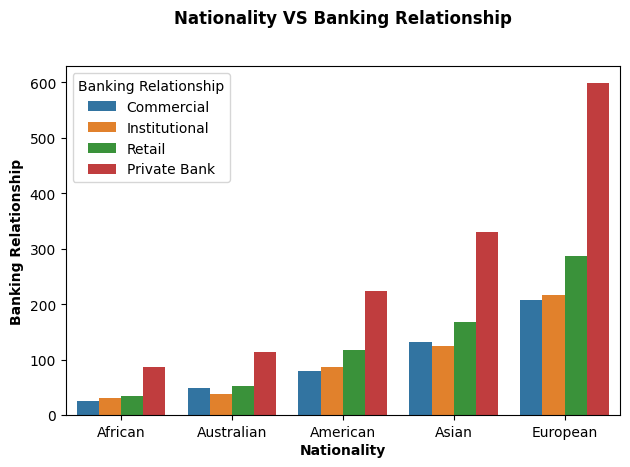

In [100]:
nation_wise_loyalty_class = df.groupby(['Nationality','Banking Relationship'])['Client ID'].count().reset_index().sort_values('Client ID')

sns.barplot( data=nation_wise_loyalty_class,
             x= 'Nationality' , 
             y= 'Client ID',
             hue='Banking Relationship',
             palette='tab10')

plt.title("Nationality VS Banking Relationship",y=1.10, fontweight='bold')
plt.xlabel('Nationality', labelpad=3.10, fontweight='bold')
plt.ylabel('Banking Relationship', fontweight='bold')
plt.tight_layout()
plt.show()

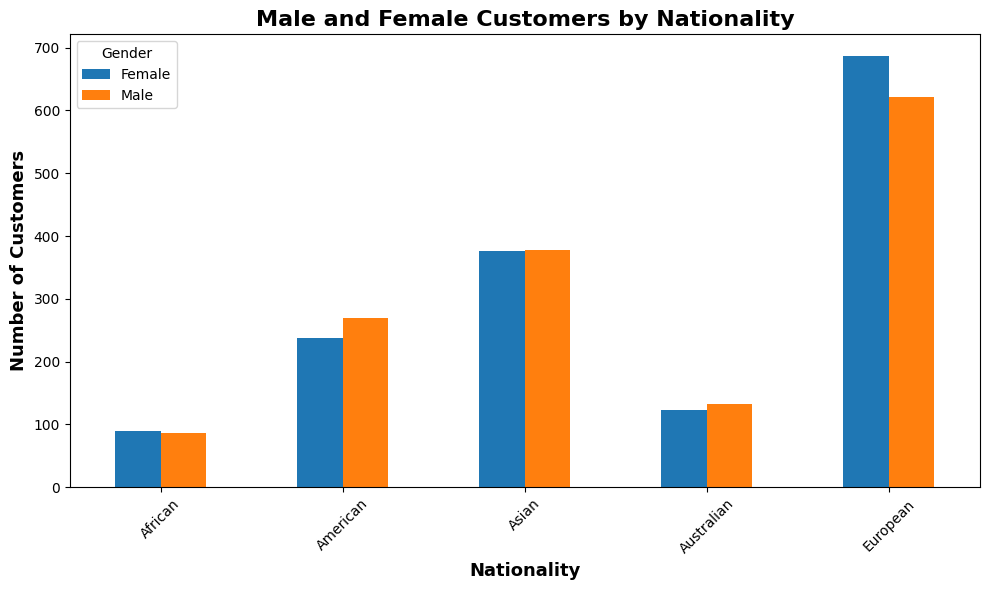

In [101]:
gender_count = pd.crosstab(df['Nationality'], df['Gender'])

gender_count.plot(kind='bar', figsize=(10,6))

plt.title("Male and Female Customers by Nationality", fontsize=16, fontweight='bold')
plt.xlabel("Nationality", fontsize=13, fontweight='bold')
plt.ylabel("Number of Customers", fontsize=13, fontweight='bold')

plt.xticks(rotation=45)
plt.yticks()

plt.legend(title='Gender')
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Net Financial Position(In Million)')

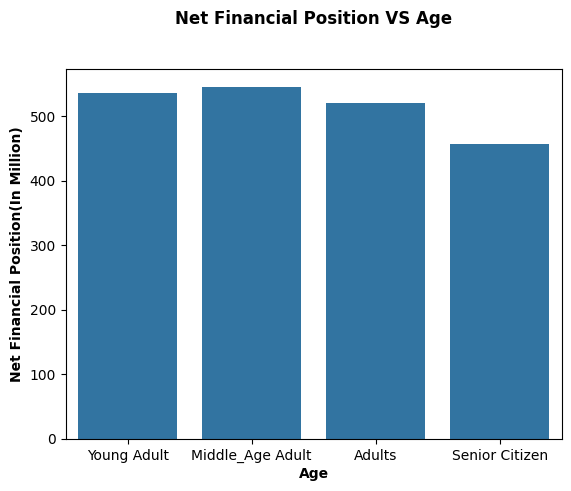

In [102]:
age_wise_financial_pos = df.groupby('Age_label')['Net Financial Position'].sum()/ 1_000_000

sns.barplot( x= age_wise_financial_pos.index , y= age_wise_financial_pos.values)
plt.title("Net Financial Position VS Age",y=1.10,fontweight='bold')
plt.xlabel("Age", labelpad=3.10,fontweight='bold')
plt.ylabel("Net Financial Position(In Million)",fontweight='bold')




In [103]:
df.columns

Index(['Client ID', 'Name', 'Age', 'Joined Bank', 'Nationality', 'Occupation',
       'Fee Structure', 'Loyalty Classification', 'Estimated Income',
       'Superannuation Savings', 'Amount of Credit Cards',
       'Credit Card Balance', 'Bank Loans', 'Bank Deposits',
       'Checking Accounts', 'Saving Accounts', 'Foreign Currency Account',
       'Business Lending', 'Properties Owned', 'Risk Weighting', 'Gender',
       'Banking Relationship', 'Investment Advisor', 'Joined Year',
       'Joined Month', 'Total Assets', 'Total Debt', 'Net Financial Position',
       'Deposit to Income Ratio', 'Loan to Income Ratio',
       'Customer Tenure (Years)', 'Age_label'],
      dtype='str')

Most of the customers are from European, Asian and American Country

<Axes: >

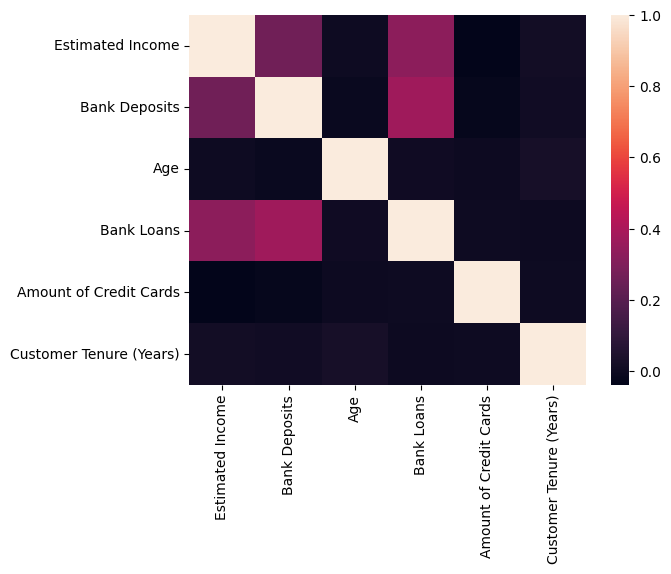

In [104]:
corr_data = df[['Estimated Income','Bank Deposits', 'Age', 'Bank Loans','Amount of Credit Cards','Customer Tenure (Years)']]
sns.heatmap(corr_data.corr(method='pearson'))

<center>

## ***Male Vs Female testing***  

</center>

<center>

### - Average deposits(t-tests)

</center>

H0 (Null Hypothesis)      :  Avg Male Deposit  = Avg Female Deposits 

H1 (Alternate Hypothesis) : Avg Male Deposit  ≠ Avg Female Deposits 

In [105]:
male_deposits = df[df['Gender']=='Male']['Bank Deposits']
female_deposits = df[df['Gender']=='Female']['Bank Deposits']

print(f'male deposits data shape {male_deposits.shape}')
print(f'female deposits data shape {female_deposits.shape}')

male deposits data shape (1488,)
female deposits data shape (1512,)


<Figure size 600x400 with 0 Axes>

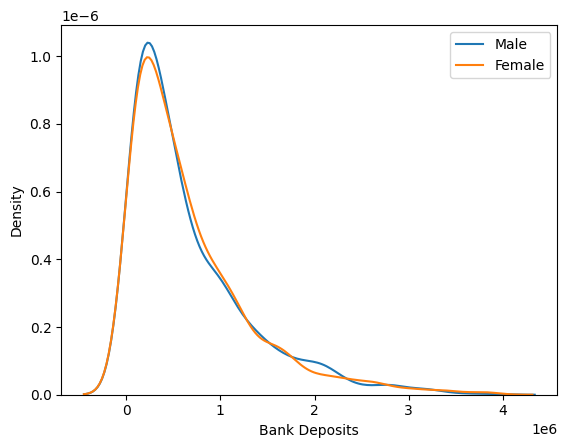

In [106]:
plt.Figure(figsize=(2,2))
sns.kdeplot(male_deposits)
sns.kdeplot(female_deposits)
plt.legend(['Male','Female'])
plt.Figure(figsize=(6,4))


In [107]:
from scipy.stats import ttest_ind

t, p = ttest_ind(
    male_deposits,
    female_deposits,
    equal_var=False
)
print(f'T-value :{t}\n')
print(f'P-Value : {p}\n')

alpha = 0.05

if p < alpha:
    print("Reject H0 (significant difference)\n")
else:
    print("Fail to reject H0 (no significant difference between Average deposit of male and female)\n")

T-value :-0.18536312569589114

P-Value : 0.8529567682927942

Fail to reject H0 (no significant difference between Average deposit of male and female)



- An independent Welch's t-test was conducted to compare average bank deposits between male (n = 1,488) and female (n = 1,512) customers. 
- The distributions were positively skewed but the large sample sizes make Welch's t-test appropriate. 
- The test indicated no statistically significant difference in mean deposits between the two groups (t = -0.184, p = 0.854).
- Therefore, we fail to reject the null hypothesis and conclude that there is no evidence of a difference in average bank deposits between male and female customers in this dataset.
- Reporting a Mann–Whitney U test is recommended to complement this finding.

<center>

### **The Mann–Whitney U test**

</center>


**The Mann–Whitney U test** (also called the Wilcoxon rank-sum test) is a non-parametric statistical test used to compare two independent groups when the data do not satisfy the assumptions of a t-test, especially the assumption of normality.

**Why is it used?**

Unlike a t-test, the Mann–Whitney U test:
- Does not assume the data are normally distributed.
- Works well with skewed data, ordinal data, or data containing outliers.
- Compares the ranks of the observations rather than their actual values.




In [108]:
from scipy.stats import mannwhitneyu

u_stat, p_value = mannwhitneyu(
    male_deposits,
    female_deposits,
    alternative="two-sided"
)

print("U Statistic:", u_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: The distributions differ.")
else:
    print("Fail to reject H0: No significant difference.")

U Statistic: 1116917.0
P-value: 0.7355839159695807
Fail to reject H0: No significant difference.


The analysis indicates that there is no statistically significant difference in the distribution of bank deposits between male and female customers. This finding is consistent with the ***Welch's t-test*** (t = −0.184, p = 0.854), which also found no significant difference in the average bank deposits between the two groups. Together, these results suggest that customer gender is not associated with meaningful differences in bank deposit amounts in this dataset.

<center>

### Gender vs Bank Loans

</center>

H0 (Null Hypothesis)      :  Avg Male loan amount  = Avg Female loan amount

H1 (Alternate Hypothesis) : Avg Male loan amount  ≠ Avg Female loan amount

<Figure size 600x400 with 0 Axes>

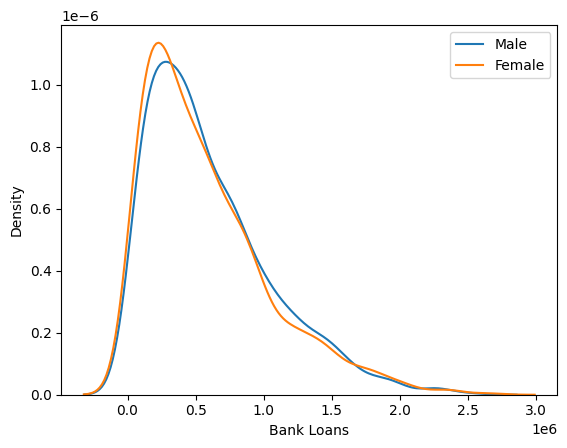

In [109]:
male_loans = df[df['Gender']=='Male']['Bank Loans']
female_loans =df[df['Gender']=='Female']['Bank Loans']

plt.Figure(figsize=(2,2))
sns.kdeplot(male_loans)
sns.kdeplot(female_loans)
plt.legend(['Male','Female'])
plt.Figure(figsize=(6,4))

In [110]:
from scipy.stats import ttest_ind

t, p = ttest_ind(
    male_loans,
    female_loans,
    equal_var=False
)
print(f'T-value :{t}\n')
print(f'P-Value : {p}\n')

alpha = 0.05

if p < alpha:
    print("Reject H0 (significant difference)\n")
else:
    print("Fail to reject H0 (no significant difference between Average loan of male and female)\n")

T-value :1.431553760314197

P-Value : 0.15237580891380695

Fail to reject H0 (no significant difference between Average loan of male and female)



The statistical analysis indicates that there is no significant difference in the average loan amounts between male and female applicants at the 5% significance level.

Although the average loan amounts may differ slightly, the observed difference is not statistically significant and could have occurred due to random variation in the sample.

<center>

### Gender vs Estimated Income

</center>

<Figure size 600x400 with 0 Axes>

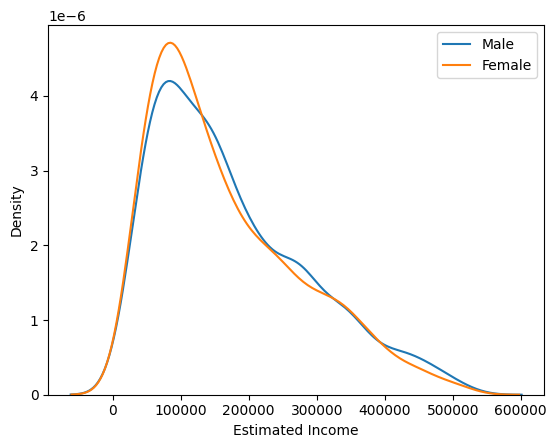

In [111]:
male_income = df[df['Gender']=='Male']['Estimated Income']
female_income =df[df['Gender']=='Female']['Estimated Income']

plt.Figure(figsize=(2,2))
sns.kdeplot(male_income )
sns.kdeplot(female_income)
plt.legend(['Male','Female'])
plt.Figure(figsize=(6,4))

In [112]:
from scipy.stats import ttest_ind

t, p = ttest_ind(
    male_income,
    female_income,
    equal_var=False
)
print(f'T-value :{t}\n')
print(f'P-Value : {p}\n')

alpha = 0.05

if p < alpha:
    print("Reject H0 (significant difference)\n")
else:
    print("Fail to reject H0 (no significant difference between Average income of male and female)\n")

T-value :1.978124894466643

P-Value : 0.04800621586785157

Reject H0 (significant difference)



In [113]:
import pingouin as pg

d = pg.compute_effsize(male_income, female_income, eftype='cohen')
print(f"Cohen's d: {d:.3f}")

if d < 0.20:
    print("Negligible effect size")
elif 0.20 <= d < 0.50:
    print("Small effect size")
elif 0.50 <= d < 0.80:
    print("Medium effect size")
else:
    print("Large effect size")

Cohen's d: 0.072
Negligible effect size


An independent samples Welch's t-test showed a statistically significant difference in average income between male and female applicants (t = -1.978, p = 0.048). However, the effect size was negligible (Cohen's d = 0.072), indicating that the practical difference in average income between the two groups is very small. Therefore, while the difference is statistically significant, it is unlikely to be of substantial practical importance.

<center>

## ***Does banking relationship affect deposits? (ANOVA - Test)***  
 
</center>

**Summary**
- ***Purpose:***  Test whether the means of three or more groups differ.
- ***Inputs:***  One continuous dependent variable and one (or more) categorical independent variables.
- ***Decision rule:***  If the p-value < 0.05, reject the null hypothesis and conclude that at least one group mean differs.
- ***Next step after significance:***  Perform a post-hoc test (e.g., Tukey's HSD) to determine exactly which groups are different.

In [114]:
retail_client = df[df['Banking Relationship']=='Retail']['Bank Deposits']

commercial__client = df[df['Banking Relationship']=='Commercial']['Bank Deposits']

Institutional__client = df[df['Banking Relationship']=='Institutional']['Bank Deposits']

Private_Bank__client = df[df['Banking Relationship']=='Private Bank']['Bank Deposits']




H0 (Null Hypothesis)      :The mean bank deposits are equal across all banking relationship groups. 

H1 (Alternate Hypothesis) : At least one group has different mean bank deposits.

In [115]:
# Checking Variance assumption for ANOVA test

print(retail_client.var())
print(commercial__client.var())
print(Institutional__client.var())
print(Private_Bank__client.var())
print('\n')
from scipy.stats import levene

stat, p = levene(retail_client,commercial__client,Institutional__client,Private_Bank__client)

print(f"Statistic: {stat:.4f}")
print(f"P-value: {p:.4f}")

356206584178.57263
423890683102.08606
410296801877.68585
446853031345.5131


Statistic: 0.4640
P-value: 0.7074


p > 0.05 → No evidence that the variances differ significantly → Standard ANOVA is appropriate.

There is no evidence that the variances differ significantly across the banking relationship groups. 
Therefore, the equal variance assumption required for one-way ANOVA is satisfied.

In [116]:
from scipy.stats import f_oneway

f_stat, p_value = f_oneway(retail_client,commercial__client,Institutional__client,Private_Bank__client)

print(f'F_stat :{f_stat}, P_Value: {p_value}\n')

if p_value < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fails to reject Null Hypothesis")

F_stat :0.6028751360293827, P_Value: 0.6131127489891299

Fails to reject Null Hypothesis


The analysis indicates that there is no statistically significant difference in the average bank deposits among Retail, Commercial, Institutional, and Private Bank customers.

This suggests that the type of banking relationship does not have a statistically significant effect on customer deposits in the available dataset.

<center>

 ### Does risk weighting differ across age groups?

</center>

H0 (Null Hypothesis)      :The mean risk weighting are equal across all age groups. 

H1 (Alternate Hypothesis) : At least one group has different mean risk weighting.

In [117]:
risk_weigh_young_adults = df[df['Age_label']=='Young Adult']['Risk Weighting']
risk_weigh_Middle_Age_Adult = df[df['Age_label']=='Middle_Age Adult']['Risk Weighting']
risk_weigh_adults = df[df['Age_label']=='Adults']['Risk Weighting']
risk_weigh_senior_citizen = df[df['Age_label']=='Senior Citizen']['Risk Weighting']


In [118]:
print(risk_weigh_young_adults.var())
print(risk_weigh_Middle_Age_Adult.var())
print(risk_weigh_adults.var())
print(risk_weigh_senior_citizen .var())
print('\n')
from scipy.stats import levene

stat, p = levene(risk_weigh_young_adults,risk_weigh_Middle_Age_Adult,risk_weigh_adults,risk_weigh_senior_citizen)

print(f"Statistic: {stat:.4f}")
print(f"P-value: {p:.4f}")

1.297590203224006
1.3055799217758328
1.1646837573708597
1.3521232259966691


Statistic: 1.7866
P-value: 0.1475


p > 0.05 → No evidence that the variances differ significantly → Standard ANOVA is appropriate.

There is no evidence that the variances differ significantly across the different age groups. 
Therefore, the equal variance assumption required for one-way ANOVA is satisfied.

In [119]:
from scipy.stats import f_oneway

f_stat, p_value = f_oneway(risk_weigh_young_adults,risk_weigh_Middle_Age_Adult,risk_weigh_adults,risk_weigh_senior_citizen)

print(f'F_stat :{f_stat}, P_Value: {p_value}\n')

if p_value < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fails to reject Null Hypothesis")

F_stat :1.1383010189596259, P_Value: 0.33215165917049194

Fails to reject Null Hypothesis


The analysis indicates that there is no statistically significant difference in the average Risk Weighting among the different age groups (Young Adult, Middle-Age Adult, Adult, and Senior Citizen).

This suggests that age group does not have a significant effect on Risk Weighting in the dataset.

<center>

 ### Does Fee structure associated with age 

</center>

In [120]:
table = pd.crosstab(df['Age_label'], df['Fee Structure'])

from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(table)

print(f"Chi-square: {chi2}\n")
print(f"p-value: {p}\n")
print(f"Degrees of freedom: {dof}\n")
print("Expected frequencies:")
print(expected)
print('\n')

alpha = 0.05

if p < alpha:
    print("Reject H0")
    print("Variables are associated")
else:
    print("Fail to reject H0")
    print("Variables are independent")

Chi-square: 11.187089083238362

p-value: 0.08276348481608398

Degrees of freedom: 6

Expected frequencies:
[[384.252      146.30733333 250.44066667]
 [375.396      142.93533333 244.66866667]
 [367.524      139.938      239.538     ]
 [348.828      132.81933333 227.35266667]]


Fail to reject H0
Variables are independent


The analysis indicates that age is not a strong factor in determining the fee structure assigned to customers. Customers from different age groups tend to have similar fee structure distributions.

This suggests that other variables—such as income, occupation, account type, transaction behavior, or customer segment—may have a stronger influence on fee structure.

In [121]:
# df.to_csv("Banking_ml.csv", index=False)|